# RQ4 — Within-corpus evaluation

Input: `../metrics/evaluation_macro_f1.csv` (project-level Macro-F1 of the six approaches on 30 projects; `results/rq4_1/within_corpus/metrics/evaluation_macro_f1.csv` when run from the repository root).

Outputs (displayed inline; no files are written): descriptive statistics, normality and omnibus tests, Holm-corrected pairwise comparisons, a compact summary table, and a pairwise effect-size heatmap.

Run: *Run All*.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

try:
    import pingouin as pg
except ImportError as exc:
    raise ImportError(
        "This notebook requires 'pingouin'. Install the "
        "dependencies from requirements.txt before running the analysis."
    ) from exc

EXPECTED_PROJECTS = 30
EXPECTED_APPROACH_COLUMNS = [
    "gpt-oss",
    "codebert",
    "flaccs",
    "bilstm",
    "svm",
    "hqcm",
]

DISPLAY_LABELS = {
    "gpt-oss": "GPT-OSS 20B",
    "codebert": "CodeBERT",
    "flaccs": "FLACCS",
    "bilstm": "BiLSTM",
    "svm": "TF-IDF + Linear SVM",
    "hqcm": "CodeFuse HQCM",
}

# Support the two common execution locations:
# 1) the notebook directory itself; and
# 2) the repository root.
DATA_CANDIDATES = [
    Path("../metrics/evaluation_macro_f1.csv"),
    Path("results/rq4_1/within_corpus/metrics/evaluation_macro_f1.csv"),
    Path("metrics/evaluation_macro_f1.csv"),
]

DATA_PATH = next(
    (candidate.resolve() for candidate in DATA_CANDIDATES if candidate.exists()),
    None,
)
if DATA_PATH is None:
    tried = "\n".join(f"  - {path}" for path in DATA_CANDIDATES)
    raise FileNotFoundError(
        "Could not locate the within-corpus evaluation CSV. Tried:\n" + tried
    )

df_raw = pd.read_csv(DATA_PATH)
df_raw.columns = df_raw.columns.str.strip()

expected_columns = ["project", *EXPECTED_APPROACH_COLUMNS]
missing_columns = [column for column in expected_columns if column not in df_raw.columns]
extra_columns = [column for column in df_raw.columns if column not in expected_columns]
if missing_columns or extra_columns:
    raise ValueError(
        "Unexpected evaluation schema. "
        f"Missing={missing_columns}; extra={extra_columns}"
    )

if len(df_raw) != EXPECTED_PROJECTS:
    raise ValueError(
        f"Expected {EXPECTED_PROJECTS} project rows, found {len(df_raw)}."
    )

if df_raw["project"].isna().any():
    raise ValueError("Project identifiers must not be missing.")

if df_raw["project"].duplicated().any():
    duplicates = df_raw.loc[
        df_raw["project"].duplicated(),
        "project",
    ].astype(str).tolist()
    raise ValueError(
        f"Duplicate project identifiers were found: {duplicates}"
    )

for column in EXPECTED_APPROACH_COLUMNS:
    df_raw[column] = pd.to_numeric(df_raw[column], errors="raise")

if df_raw[EXPECTED_APPROACH_COLUMNS].isna().any().any():
    missing = df_raw[EXPECTED_APPROACH_COLUMNS].isna().sum()
    missing = missing[missing > 0].to_dict()
    raise ValueError(f"Evaluation contains missing Macro-F1 values: {missing}")

invalid_mask = (
    (df_raw[EXPECTED_APPROACH_COLUMNS] < 0)
    | (df_raw[EXPECTED_APPROACH_COLUMNS] > 1)
)
if invalid_mask.any().any():
    raise ValueError("Evaluation Macro-F1 values must lie in the [0, 1] interval.")

# Keep the frozen approach order from the evaluation definition.
df_clean = (
    df_raw.set_index("project")[EXPECTED_APPROACH_COLUMNS]
    .rename(columns=DISPLAY_LABELS)
    .copy()
)

print(f"Data file: {DATA_PATH}")
print(f"Complete paired projects: {len(df_clean)}")
print(f"Evaluation approaches ({len(df_clean.columns)}): {df_clean.columns.tolist()}")

display(df_clean.head())


def _round_small(frame, decimals):
    """Round for display; nonzero values that round to 0 are shown as <0.001."""
    rounded = frame.round(decimals)
    out = rounded.astype(object)
    for column in frame.select_dtypes("number").columns:
        tiny = (frame[column] != 0) & (rounded[column] == 0)
        out.loc[tiny, column] = "<0.001"
    return out


Data file: results\rq4_1\within_corpus\metrics\evaluation_macro_f1.csv
Complete paired projects: 30
Evaluation approaches (6): ['GPT-OSS 20B', 'CodeBERT', 'FLACCS', 'BiLSTM', 'TF-IDF + Linear SVM', 'CodeFuse HQCM']


,GPT-OSS 20B,CodeBERT,FLACCS,BiLSTM,TF-IDF + Linear SVM,CodeFuse HQCM
project,,,,,,
angular,0.400705,0.664170,0.448144,0.590194,0.506429,0.180000
ant-design,0.493764,0.704543,0.336930,0.626326,0.533766,0.193395
biome,0.520181,0.468211,0.468274,0.462280,0.411800,0.119048
bun,0.566036,0.596101,0.455556,0.507835,0.548840,0.111111
clap,0.538139,0.576326,0.693497,0.675147,0.463371,0.258838


## Analysis functions

In [2]:
from itertools import combinations
from scipy.stats import friedmanchisquare, shapiro, t, ttest_rel


def _format_p_plain(p_value, digits=4):
    p_value = float(p_value)
    if p_value < 0.001:
        return "<.001"
    return f"{p_value:.{digits}f}".lstrip("0")


def _effect_magnitude(effect, route):
    value = abs(float(effect))

    if route == "parametric":
        if value < 0.2:
            return "Negligible"
        if value < 0.5:
            return "Small"
        if value < 0.8:
            return "Medium"
        return "Large"

    if value < 0.1:
        return "Negligible"
    if value < 0.3:
        return "Small"
    if value < 0.5:
        return "Medium"
    return "Large"


def _sphericity_values(result):
    """Support named and tuple-like Pingouin return objects."""
    names = ("spher", "W", "chi2", "dof", "pval")
    if all(hasattr(result, name) for name in names):
        return {name: getattr(result, name) for name in names}

    return dict(zip(names, result))


def _pingouin_value(row, *candidates):
    normalized = {
        str(column).lower().replace("-", "_"): column
        for column in row.index
    }
    for candidate in candidates:
        key = candidate.lower().replace("-", "_")
        if key in normalized:
            return row[normalized[key]]
    raise KeyError(
        f"None of these columns were found: {candidates}"
    )


def _descriptive_table(data):
    n = len(data)
    means = data.mean()
    standard_deviations = data.std(ddof=1)
    standard_errors = standard_deviations / np.sqrt(n)
    critical_t = t.ppf(0.975, df=n - 1)
    mean_ranks = data.rank(
        axis=1,
        method="average",
        ascending=False,
    ).mean()

    table = pd.DataFrame({
        "N": n,
        "Mean Macro-F1": means,
        "SD": standard_deviations,
        "CI95 Lower": means - critical_t * standard_errors,
        "CI95 Upper": means + critical_t * standard_errors,
        "Mean Rank": mean_ranks,
    })

    return table.sort_values(
        ["Mean Rank", "Mean Macro-F1"],
        ascending=[True, False],
    )


def _pairwise_tests(data, route, alpha):
    rows = []

    for model_a, model_b in combinations(data.columns, 2):
        values_a = data[model_a].to_numpy()
        values_b = data[model_b].to_numpy()

        if route == "parametric":
            statistic, p_value = ttest_rel(values_a, values_b)

            if np.allclose(values_a - values_b, 0):
                effect = 0.0
            else:
                effect = pg.compute_effsize(
                    values_a,
                    values_b,
                    paired=True,
                    eftype="hedges",
                )

            statistic_name = "t"
            effect_name = "Hedges' g"
        else:
            if np.allclose(values_a - values_b, 0):
                statistic = 0.0
                p_value = 1.0
                effect = 0.0
            else:
                wilcoxon = pg.wilcoxon(
                    values_a,
                    values_b,
                    alternative="two-sided",
                ).iloc[0]
                statistic = _pingouin_value(
                    wilcoxon,
                    "W_val",
                    "W-val",
                )
                p_value = _pingouin_value(
                    wilcoxon,
                    "p_val",
                    "p-val",
                )
                effect = _pingouin_value(wilcoxon, "RBC")

            statistic_name = "W"
            effect_name = "Rank-biserial correlation"

        rows.append({
            "A": model_a,
            "B": model_b,
            "Mean A": float(np.mean(values_a)),
            "Mean B": float(np.mean(values_b)),
            "Statistic name": statistic_name,
            "Statistic": float(statistic),
            "p_raw": float(p_value),
            "Effect name": effect_name,
            "Effect": float(effect),
        })

    pairwise = pd.DataFrame(rows)
    reject, corrected_p = pg.multicomp(
        pairwise["p_raw"].to_numpy(),
        alpha=alpha,
        method="holm",
    )
    pairwise["p_Holm"] = corrected_p
    pairwise["Significant"] = reject
    pairwise["Winner"] = np.where(
        pairwise["Effect"] >= 0,
        pairwise["A"],
        pairwise["B"],
    )
    pairwise["Loser"] = np.where(
        pairwise["Effect"] >= 0,
        pairwise["B"],
        pairwise["A"],
    )
    pairwise["Absolute effect"] = pairwise["Effect"].abs()
    pairwise["Effect magnitude"] = pairwise["Effect"].map(
        lambda value: _effect_magnitude(value, route)
    )

    return pairwise


def run_model_comparison(data, alpha=0.05):
    descriptive = _descriptive_table(data)

    shapiro_rows = []
    for model in data.columns:
        statistic, p_value = shapiro(data[model])
        shapiro_rows.append({
            "Model": model,
            "N": int(data[model].notna().sum()),
            "W": float(statistic),
            "p": float(p_value),
            "Normality not rejected": bool(p_value >= alpha),
        })

    shapiro_results = pd.DataFrame(shapiro_rows).set_index("Model")
    all_normal = bool(
        shapiro_results["Normality not rejected"].all()
    )
    route = "parametric" if all_normal else "non-parametric"

    n_projects = len(data)
    n_models = len(data.columns)
    sphericity = None

    if route == "parametric":
        long_data = (
            data.rename_axis("Project")
            .reset_index()
            .melt(
                id_vars="Project",
                var_name="Model",
                value_name="Macro-F1",
            )
        )

        sphericity = _sphericity_values(
            pg.sphericity(
                data=long_data,
                dv="Macro-F1",
                within="Model",
                subject="Project",
            )
        )

        anova = pg.rm_anova(
            data=long_data,
            dv="Macro-F1",
            within="Model",
            subject="Project",
            correction=True,
            detailed=True,
            effsize="ng2",
        )
        anova_row = anova.iloc[0]
        statistic = float(_pingouin_value(anova_row, "F"))
        p_uncorrected = float(
            _pingouin_value(anova_row, "p_unc", "p-unc")
        )
        epsilon = float(_pingouin_value(anova_row, "eps"))
        effect = float(_pingouin_value(anova_row, "ng2"))

        if float(sphericity["pval"]) < alpha:
            p_value = float(
                _pingouin_value(
                    anova_row,
                    "p_GG_corr",
                    "p-GG-corr",
                )
            )
            df1 = epsilon * (n_models - 1)
            df2 = epsilon * (n_models - 1) * (n_projects - 1)
            correction = "Greenhouse-Geisser"
        else:
            p_value = p_uncorrected
            df1 = n_models - 1
            df2 = (n_models - 1) * (n_projects - 1)
            correction = "None"

        omnibus = {
            "test": "Repeated-measures ANOVA",
            "statistic name": "F",
            "statistic": statistic,
            "df1": float(df1),
            "df2": float(df2),
            "p": p_value,
            "effect name": "eta_G_squared",
            "effect": effect,
            "epsilon": epsilon,
            "correction": correction,
            "significant": bool(p_value < alpha),
        }
    else:
        statistic, p_value = friedmanchisquare(
            *[data[column].to_numpy() for column in data.columns]
        )
        kendalls_w = statistic / (
            n_projects * (n_models - 1)
        )
        omnibus = {
            "test": "Friedman",
            "statistic name": "chi-square",
            "statistic": float(statistic),
            "df1": float(n_models - 1),
            "df2": np.nan,
            "p": float(p_value),
            "effect name": "Kendall's W",
            "effect": float(kendalls_w),
            "epsilon": np.nan,
            "correction": "Not applicable",
            "significant": bool(p_value < alpha),
        }

    if omnibus["significant"]:
        pairwise = _pairwise_tests(data, route, alpha)
        significant_pairwise = pairwise.loc[
            pairwise["Significant"]
        ].copy()
    else:
        pairwise = None
        significant_pairwise = None

    leader = descriptive.index[0]
    not_distinguishable = [leader]

    if pairwise is not None:
        for model in descriptive.index[1:]:
            comparison = pairwise.loc[
                (
                    (pairwise["A"] == leader)
                    & (pairwise["B"] == model)
                )
                | (
                    (pairwise["A"] == model)
                    & (pairwise["B"] == leader)
                )
            ]
            if len(comparison) != 1:
                raise ValueError(
                    "Missing or duplicated leader comparison for "
                    f"{model}."
                )
            if not bool(comparison.iloc[0]["Significant"]):
                not_distinguishable.append(model)

    summary = descriptive.copy()
    if pairwise is None:
        summary["Not significantly different from leader"] = pd.NA
    else:
        summary["Not significantly different from leader"] = [
            model in not_distinguishable
            for model in summary.index
        ]

    print("DESCRIPTIVE APPROACH TABLE")
    display(_round_small(summary, {
        "Mean Macro-F1": 4,
        "SD": 4,
        "CI95 Lower": 4,
        "CI95 Upper": 4,
        "Mean Rank": 2,
    }))

    print("SHAPIRO-WILK TESTS")
    shapiro_display = shapiro_results.copy()
    shapiro_display["W"] = shapiro_display["W"].round(4)
    shapiro_display["p"] = shapiro_display["p"].map(
        _format_p_plain
    )
    display(shapiro_display)

    print(f"SELECTED ROUTE: {route}")
    display(pd.DataFrame([omnibus]))

    if pairwise is None:
        pass
    else:
        print(
            "SIGNIFICANT HOLM-CORRECTED PAIRWISE COMPARISONS "
            f"({len(significant_pairwise)} of {len(pairwise)})"
        )
        pairwise_display = significant_pairwise.copy()
        pairwise_display["p_raw"] = pairwise_display["p_raw"].map(
            _format_p_plain
        )
        pairwise_display["p_Holm"] = pairwise_display[
            "p_Holm"
        ].map(_format_p_plain)
        display(_round_small(pairwise_display, {
            "Mean A": 4,
            "Mean B": 4,
            "Statistic": 4,
            "Effect": 4,
        }))

    return {
        "data": data,
        "descriptive": descriptive,
        "summary": summary,
        "shapiro": shapiro_results,
        "route": route,
        "sphericity": sphericity,
        "omnibus": omnibus,
        "pairwise": pairwise,
        "significant_pairwise": significant_pairwise,
        "leader": leader,
        "not_distinguishable": not_distinguishable,
        "alpha": alpha,
    }


## Run the analysis

In [3]:
evaluation_analysis = run_model_comparison(df_clean)

if evaluation_analysis["sphericity"] is not None:
    print("MAUCHLY'S TEST OF SPHERICITY")
    display(_round_small(pd.DataFrame([{
        "Mauchly W": evaluation_analysis["sphericity"]["W"],
        "chi-square": evaluation_analysis["sphericity"]["chi2"],
        "df": evaluation_analysis["sphericity"]["dof"],
        "p": evaluation_analysis["sphericity"]["pval"],
    }]), 4))


DESCRIPTIVE APPROACH TABLE


,N,Mean Macro-F1,SD,CI95 Lower,CI95 Upper,Mean Rank,Not significantly different from leader
CodeBERT,30,0.5828,0.1469,0.528,0.6377,1.87,True
BiLSTM,30,0.5166,0.1068,0.4768,0.5565,2.9,False
TF-IDF + Linear SVM,30,0.4986,0.1226,0.4528,0.5444,3.07,False
GPT-OSS 20B,30,0.489,0.1434,0.4355,0.5425,3.07,False
FLACCS,30,0.4193,0.1065,0.3795,0.4591,4.1,False
CodeFuse HQCM,30,0.1797,0.0815,0.1493,0.2102,6.0,False


SHAPIRO-WILK TESTS


,N,W,p,Normality not rejected
Model,,,,
GPT-OSS 20B,30,0.9670,.4596,True
CodeBERT,30,0.9498,.1667,True
FLACCS,30,0.9676,.4762,True
BiLSTM,30,0.9713,.5750,True
TF-IDF + Linear SVM,30,0.9697,.5321,True
CodeFuse HQCM,30,0.9444,.1194,True


SELECTED ROUTE: parametric


,test,statistic name,statistic,df1,df2,p,effect name,effect,epsilon,correction,significant
0,Repeated-measures ANOVA,F,71.777329,3.515162,101.93971,4.496582e-27,eta_G_squared,0.544249,0.703032,Greenhouse-Geisser,True


SIGNIFICANT HOLM-CORRECTED PAIRWISE COMPARISONS (12 of 15)


,A,B,Mean A,Mean B,Statistic name,Statistic,p_raw,Effect name,Effect,p_Holm,Significant,Winner,Loser,Absolute effect,Effect magnitude
0,GPT-OSS 20B,CodeBERT,0.489,0.5828,t,-3.3599,.0022,Hedges' g,-0.6379,.0132,True,CodeBERT,GPT-OSS 20B,0.637933,Medium
1,GPT-OSS 20B,FLACCS,0.489,0.4193,t,3.4282,.0018,Hedges' g,0.5444,.0129,True,GPT-OSS 20B,FLACCS,0.544406,Medium
4,GPT-OSS 20B,CodeFuse HQCM,0.489,0.1797,t,13.0321,<.001,Hedges' g,2.6177,<.001,True,GPT-OSS 20B,CodeFuse HQCM,2.617695,Large
5,CodeBERT,FLACCS,0.5828,0.4193,t,6.1878,<.001,Hedges' g,1.2574,<.001,True,CodeBERT,FLACCS,1.257429,Large
6,CodeBERT,BiLSTM,0.5828,0.5166,t,3.2576,.0029,Hedges' g,0.5088,.0143,True,CodeBERT,BiLSTM,0.508811,Medium
7,CodeBERT,TF-IDF + Linear SVM,0.5828,0.4986,t,3.9907,<.001,Hedges' g,0.6144,.0033,True,CodeBERT,TF-IDF + Linear SVM,0.614374,Medium
8,CodeBERT,CodeFuse HQCM,0.5828,0.1797,t,16.0949,<.001,Hedges' g,3.349,<.001,True,CodeBERT,CodeFuse HQCM,3.348969,Large
9,FLACCS,BiLSTM,0.4193,0.5166,t,-4.6135,<.001,Hedges' g,-0.9004,<.001,True,BiLSTM,FLACCS,0.900434,Large
10,FLACCS,TF-IDF + Linear SVM,0.4193,0.4986,t,-2.8681,.0076,Hedges' g,-0.6814,.0305,True,TF-IDF + Linear SVM,FLACCS,0.681382,Medium
11,FLACCS,CodeFuse HQCM,0.4193,0.1797,t,12.2557,<.001,Hedges' g,2.4936,<.001,True,FLACCS,CodeFuse HQCM,2.493624,Large


MAUCHLY'S TEST OF SPHERICITY


,Mauchly W,chi-square,df,p
0,0.3756,26.5361,14,0.0225


## Compact table

In [4]:
compact_table = evaluation_analysis["summary"][[
    "Mean Macro-F1",
    "SD",
    "Mean Rank",
    "Not significantly different from leader",
]].copy()

display(_round_small(compact_table, {
    "Mean Macro-F1": 3,
    "SD": 3,
    "Mean Rank": 2,
}))


,Mean Macro-F1,SD,Mean Rank,Not significantly different from leader
CodeBERT,0.583,0.147,1.87,True
BiLSTM,0.517,0.107,2.9,False
TF-IDF + Linear SVM,0.499,0.123,3.07,False
GPT-OSS 20B,0.489,0.143,3.07,False
FLACCS,0.419,0.107,4.1,False
CodeFuse HQCM,0.18,0.081,6.0,False


## Holm-corrected pairwise effect-size heatmap

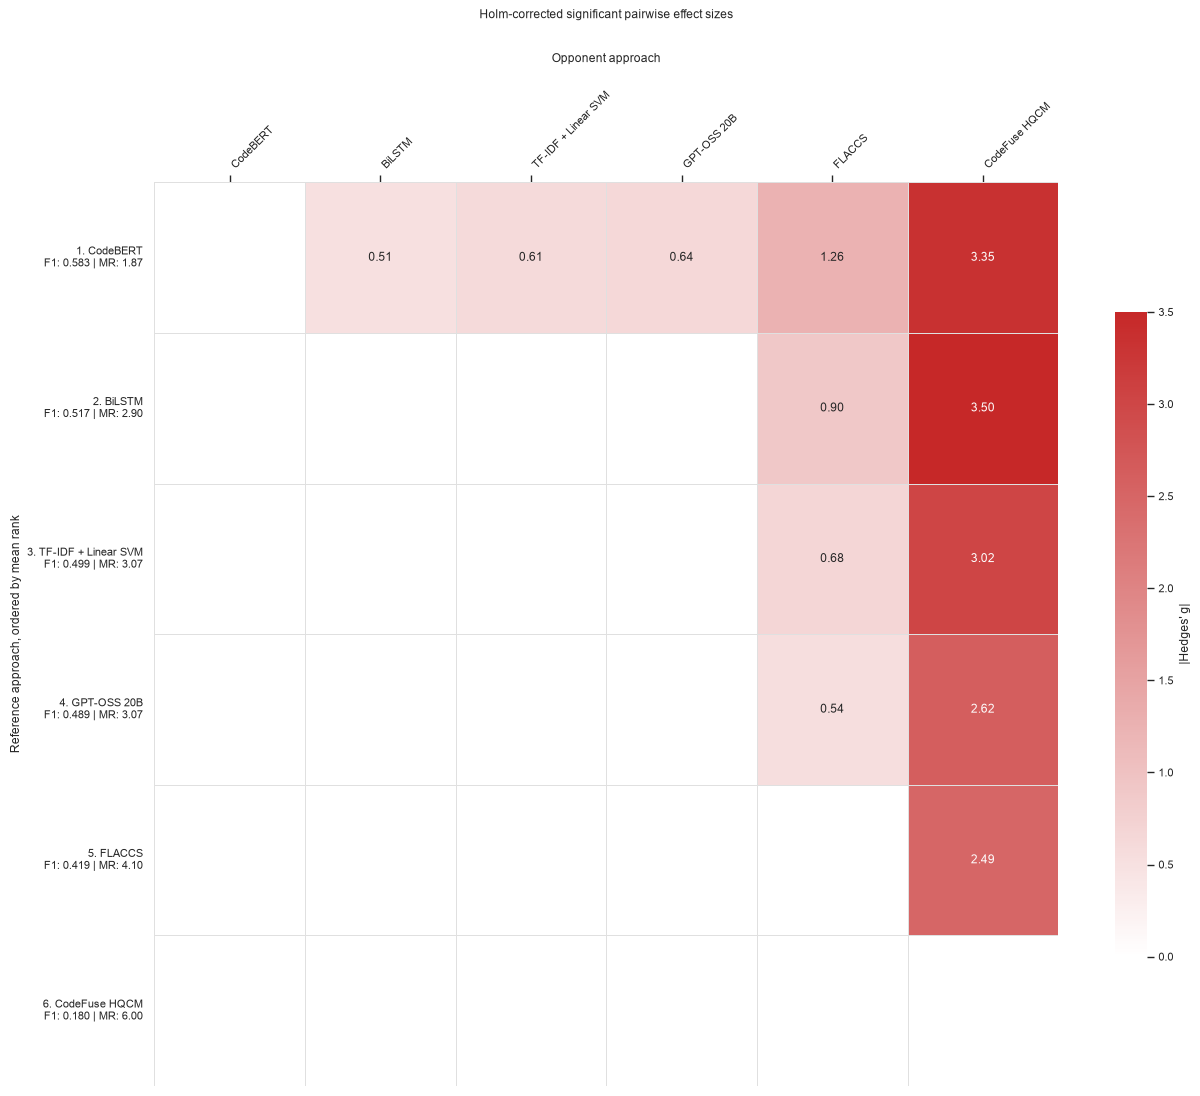

In [5]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns

pairwise = evaluation_analysis["pairwise"]

if pairwise is None:
    pass
else:
    ordered_models = evaluation_analysis["descriptive"].index.tolist()
    effect_matrix = pd.DataFrame(
        np.nan,
        index=ordered_models,
        columns=ordered_models,
    )
    p_matrix = effect_matrix.copy()

    for _, row in pairwise.iterrows():
        model_a = row["A"]
        model_b = row["B"]
        effect = row["Effect"]
        p_value = row["p_Holm"]

        effect_matrix.loc[model_a, model_b] = effect
        effect_matrix.loc[model_b, model_a] = -effect
        p_matrix.loc[model_a, model_b] = p_value
        p_matrix.loc[model_b, model_a] = p_value

    display_matrix = effect_matrix.copy()
    annotations = pd.DataFrame(
        "",
        index=ordered_models,
        columns=ordered_models,
    )

    for row_index in range(len(ordered_models)):
        for column_index in range(len(ordered_models)):
            p_value = p_matrix.iloc[row_index, column_index]
            value = effect_matrix.iloc[row_index, column_index]

            if (
                column_index > row_index
                and pd.notna(p_value)
                and p_value < evaluation_analysis["alpha"]
            ):
                annotations.iloc[
                    row_index,
                    column_index,
                ] = f"{value:.2f}"
            else:
                display_matrix.iloc[
                    row_index,
                    column_index,
                ] = np.nan

    diagonal_and_lower = np.tril(
        np.ones(display_matrix.shape, dtype=bool),
        k=0,
    )

    row_labels = []
    for position, model in enumerate(ordered_models, start=1):
        row = evaluation_analysis["descriptive"].loc[model]
        row_labels.append(
            f"{position}. {model}\n"
            f"F1: {row['Mean Macro-F1']:.3f} | "
            f"MR: {row['Mean Rank']:.2f}"
        )

    sns.set_theme(style="white", context="paper", font_scale=0.9)
    figure_size = max(11, 0.9 * len(ordered_models))
    fig, ax = plt.subplots(
        figsize=(figure_size + 2, figure_size),
    )

    color_map = LinearSegmentedColormap.from_list("white_red", ["#ffffff", "#c62828"])
    effect_label = (
        "|Hedges' g|"
        if evaluation_analysis["route"] == "parametric"
        else r"Rank-biserial correlation ($|r_{rb}|$)"
    )
    effect_limit = (
        max(1.0, float(pairwise["Effect"].abs().max()))
        if evaluation_analysis["route"] == "parametric"
        else 1.0
    )

    sns.heatmap(
        display_matrix.abs(),
        annot=annotations,
        fmt="",
        mask=diagonal_and_lower,
        cmap=color_map,
        vmin=0,
        vmax=effect_limit,
        square=True,
        linewidths=0.6,
        linecolor="#e0e0e0",
        cbar_kws={"label": effect_label, "shrink": 0.7},
        ax=ax,
    )

    ax.set_xticklabels(
        ordered_models,
        rotation=45,
        ha="left",
    )
    ax.set_yticklabels(row_labels, rotation=0)
    ax.xaxis.tick_top()
    ax.xaxis.set_label_position("top")
    ax.set_xlabel("Opponent approach", labelpad=20)
    ax.set_ylabel("Reference approach, ordered by mean rank")
    ax.set_title(
        "Holm-corrected significant pairwise effect sizes",
        pad=25,
    )

    fig.tight_layout()
    plt.show()
